In [1]:
%matplotlib inline

In [2]:
from NbodyIMRI import tools, particles, simulator, reader
from NbodyIMRI import units as u
from NbodyIMRI import distributionfunctions as DF
import NbodyIMRI

import h5py
import os
from glob import glob
from pathlib import Path
import gc
import warnings
import copy

import pandas as pd
import numpy as np

import utilities

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset, zoomed_inset_axes
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
# Use TeX
from matplotlib import rc
rc('text', usetex=True)
rc('font', family='serif')


#----- MATPLOTLIB paramaters ---------
mpl.rcParams.update({'font.size': 16,'font.family':'serif'})

mpl.rcParams['axes.labelsize'] = 16
mpl.rcParams['axes.titlesize'] = 16

mpl.rcParams['xtick.labelsize'] = 16
mpl.rcParams['ytick.labelsize'] = 16

mpl.rcParams['xtick.major.size'] = 7
mpl.rcParams['xtick.major.width'] = 1

mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.minor.width'] = 1

mpl.rcParams['ytick.major.size'] = 7
mpl.rcParams['ytick.major.width'] = 1

mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.minor.width'] = 1

mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['savefig.dpi'] = 1500

mpl.rcParams['figure.autolayout'] = False
#--------------------------------------


In [4]:
palette=["green", "#206AA3","#461220"]
palette_shades=[ "#7ADB6F", "#88BEE7","#D96D8A"]
mycolor=palette[2]
myshade=palette_shades[2]

In [5]:
u.ms= 10**-3*u.s
G_N = 6.674e-11  #SI: N*m^2/kg^2
rho_eq = 1512.0*u.Msun/u.pc**3 
t_eq=60e3*u.yr
rho_bkg= 0.34*u.GeV/u.cm**3

### Parameters for System C (NM1991)

In [6]:

dTobs=-20.7
dTerr=12.7

M_1 = 11*u.Msun
M_2 = 0.89*u.Msun

r_isco = tools.calc_risco(M_1)  # 6GM/c^2

r_s=r_isco/3.
r_orb= 1.24e-7*u.pc
a_i = r_orb
e_i = 0.0
r_star= 2.4e-8*u.pc
r_2= r_star

rho_bkg= 0.41*u.GeV/u.cm**3
T_orb = tools.calc_Torb(a_i = a_i, M_tot = M_1+M_2)
v_orb=2*np.pi * r_orb/T_orb

In [7]:
#simulation parameters
r_t  = 20*a_i   #Artificial truncation radius of the spike
r_max=1e-4*u.pc

eps1 = 3e3*r_isco

### Read simulation files

In [8]:
# Initialize the main dictionary to store all data
data_dict={}
#Initialize the dictionary to store the long run (15k orbits)
data_long={}

In [9]:
#list of simulated values for gamma
gammalist=[1.90 , 1.95, 2.00 , 2.05, 2.10 ,2.15, 2.20, 2.25, 2.30, 2.35, 2.40, 2.45]

#datasets to be read (not the DM positions)
target_sets = {'data/M_1', 'data/M_2', 'data/t', 'data/vBH1', 'data/vBH2', 'data/xBH1', 'data/xBH2' }

#Specify the directory where snapshots are stored
path_to_folder= "~/Desktop/LXMB-sim-results/NM1991/6000orbs//"
path_long_run="~/Desktop/LXMB-sim-results/NM1991/long_run/"

# radial bin including the orbital radius
n_central_bin=30

#orbits between snapshots
d_saved_snapshots=10 

#gamma value of the long run
g_long=2.40

Read the content of the simulation data. On top of the target data sets (**target_sets**) already present in the files, the function read_all_files computes and stores in the dictionary: 
- the relative BH velocities **"vBH"** and positions **"xBH"**
- the semi-major axis and eccentricities **"a"**, **"e"**
- the orbital period **"Torb"**

- it reads the density profiles and stores them in **"profiles"** and **"profile_bins"**

- the density at the orbital radius (central bin) is stored in **"rho_c"**





In [10]:
utilities.read_all_files(gammalist, path_to_folder, target_sets, data_dict, n_central_bin, r=1)

reading files for gamma=1.9
reading files for gamma=1.95
reading files for gamma=2.0
reading files for gamma=2.05
reading files for gamma=2.1
reading files for gamma=2.15
reading files for gamma=2.2
reading files for gamma=2.25
reading files for gamma=2.3
reading files for gamma=2.35
reading files for gamma=2.4
reading files for gamma=2.45


In [11]:
# Read data and profiles for the long run
utilities.read_all_files([g_long], path_long_run, target_sets, data_long, n_central_bin, r=5)

reading files for gamma=2.4
Error reading data re_re_re_re_re_2d1dD.hdf5: Unable to open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Error reading profiles re_re_re_re_re_2d1dD_profiles.hdf5: '2d1dD'
Error reading reload 2d1dD: '2d1dD'
Error reading data re_re_re_re_re_5A802.hdf5: Unable to open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Error reading profiles re_re_re_re_re_5A802_profiles.hdf5: '5A802'
Error reading reload 5A802: '5A802'
Error reading data re_re_re_re_re_Fb02e.hdf5: Unable to open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Error reading profiles re_re_re_re_re_Fb02e_profiles.hdf5: 'Fb02e'
Error reading reload Fb02e: 'Fb02e'
Error reading data re_re_re_re_re_a5db9.hdf5: Unable to open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Error reading profiles re_re_re_re_re_a

List the simulation IDs for one value of $\gamma$

In [12]:
data_dict[1.9].keys()

dict_keys(['24a7a', '2628D', '2Dceb', '46F6c', '49af3', '5AbeD', '675Fb', '8A035', 'Af6AD', 'D40ED', 'D6BeD', 'b0574', 'c6eE3', 'ee40D', 'f0AaD', 'fAc2C'])

List the dictionary entries for one of the simulations

In [13]:
data_dict[1.9]['24a7a'].keys()

dict_keys(['data/M_1', 'data/M_2', 'data/t', 'data/vBH1', 'data/vBH2', 'data/xBH1', 'data/xBH2', 'profiles', 'profile_bins', 'xBH', 'vBH', 'a', 'e', 'Torb', 'rho_c'])

Now I compute averages over realisations for some key parameters

In [14]:
keys_to_average=["rho_c", "Torb", "data/t", "a", "e", "profiles", "profile_bins"]

In [15]:
for gamma in gammalist:
    
    data=data_dict[gamma]
    utilities.average_across_realisations(data, keys_to_average)

In [16]:
for gamma in [g_long]:
    data=data_long[gamma]
    utilities.average_across_realisations(data, keys_to_average)


If I list the entries for one value of $\gamma$ again, I have added **"average"** to the list of IDs. 

In [17]:
data_dict[1.9].keys()

dict_keys(['24a7a', '2628D', '2Dceb', '46F6c', '49af3', '5AbeD', '675Fb', '8A035', 'Af6AD', 'D40ED', 'D6BeD', 'b0574', 'c6eE3', 'ee40D', 'f0AaD', 'fAc2C', 'average'])

In [18]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins'])

Next, I compute moving average to smooth the period and density decay.

In [19]:
columns_moving_average = ['Torb', 'rho_c']

I set the window size in number of orbits. I have saved one snapshot every ten orbits, so a window_size of 1 means the average is taken over 10 orbits.

In [20]:
window_orbits=1000  
window_size=int(window_orbits/d_saved_snapshots )   #default window is 100 snapshots, corresponding to 1k orbits
print(window_size)

100


In [21]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]     
            utilities.calculate_moving_averages(data, columns_moving_average, window_size)        

In [22]:
for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):

            data=data_long[gamma][IDhash]
            utilities.calculate_moving_averages(data, columns_moving_average, window_size)                                                           

With this I have added the columnns **'Torb_average'** and **'rho_c_average'**

In [23]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average'])

I read the time difference between subsequent snapshots (I take the average for simplicity but this is the same for all realisations). I also define the array of time values t_array.

In [24]:
timestep= data_dict[gammalist[0]]["average"]["data/t"][1]

timesteps_per_year=int(u.yr/timestep)

t_array =data_dict[1.9]["average"]["data/t"]

t_array_long =data_long[g_long]["average"]["data/t"]

print(timestep/u.yr)

0.01183413321169349


In [25]:
for ID in data_dict[gammalist[0]].keys():
    print (data_dict[gammalist[0]][ID]["data/t"][1]/u.yr)

0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349
0.01183413321169349


Now I compute differentials

(data["key"][n+1]-data["key"][n])/(timestep)

of the density and period, including the two smoothed out columns. Timestep is the time difference between successive snapshots.

In [26]:
keys_to_diff=["rho_c", "Torb", '(Torb)_average', '(rho_c)_average']

In [27]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]     
            utilities.calculate_differentials(data, keys_to_diff, timestep)

for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):

            data=data_long[gamma][IDhash]
            utilities.calculate_differentials(data, keys_to_diff, timestep)

I have added the columns **'diff_rho_c'**, **'diff_Torb'**, **'diff_Torb_average'** and **'diff_rho_c_average'** (the average suffix here indicates the moving average over time has been taken)

In [28]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average', 'diff_[rho_c]', 'diff_[Torb]', 'diff_[(Torb)_average]', 'diff_[(rho_c)_average]'])

I take the moving average of the differentals. This time I average over 300 orbits.

In [29]:
columns_second_moving_average = ['diff_[(Torb)_average]', 'diff_[(rho_c)_average]']
window_2=30

In [30]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]     
            utilities.calculate_moving_averages(data, columns_second_moving_average, window_size=window_2)     
            
            
for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):

            data=data_long[gamma][IDhash]
            utilities.calculate_moving_averages(data, columns_second_moving_average, window_size=window_2) 

In [31]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average', 'diff_[rho_c]', 'diff_[Torb]', 'diff_[(Torb)_average]', 'diff_[(rho_c)_average]', '(diff_[(Torb)_average])_average', '(diff_[(rho_c)_average])_average'])

I compute the second derivatives differentiating again these moving averaged quantities

In [32]:
columns_second_derivative = ['(diff_[(Torb)_average])_average', '(diff_[(rho_c)_average])_average']


In [33]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]     
            utilities.calculate_differentials(data, columns_second_derivative, timestep)

for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):

            data=data_long[gamma][IDhash]
            utilities.calculate_differentials(data, columns_second_derivative, timestep)

In [34]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average', 'diff_[rho_c]', 'diff_[Torb]', 'diff_[(Torb)_average]', 'diff_[(rho_c)_average]', '(diff_[(Torb)_average])_average', '(diff_[(rho_c)_average])_average', 'diff_[(diff_[(Torb)_average])_average]', 'diff_[(diff_[(rho_c)_average])_average]'])

I take the moving average of the derivatives, with a window of 1000 again.

In [35]:
columns_third_moving_average = ['diff_[(diff_[(Torb)_average])_average]', 'diff_[(diff_[(rho_c)_average])_average]']

In [36]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]     
            utilities.calculate_moving_averages(data, columns_third_moving_average, window_size)     
            
            
for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):

            data=data_long[gamma][IDhash]
            utilities.calculate_moving_averages(data, columns_third_moving_average, window_size) 

In [37]:
data_dict[1.9]["average"].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average', 'diff_[rho_c]', 'diff_[Torb]', 'diff_[(Torb)_average]', 'diff_[(rho_c)_average]', '(diff_[(Torb)_average])_average', '(diff_[(rho_c)_average])_average', 'diff_[(diff_[(Torb)_average])_average]', 'diff_[(diff_[(rho_c)_average])_average]', '(diff_[(diff_[(Torb)_average])_average])_average', '(diff_[(diff_[(rho_c)_average])_average])_average'])

This has become very complicated so I do some renaming

In [38]:
for gamma in gammalist:
    for IDhash in list(data_dict[gamma].keys()):
                            
            data=data_dict[gamma][IDhash]
            data["Pdot"]= data.pop('diff_[(Torb)_average]')
            data["Pdot_smoothed"]= data.pop('(diff_[(Torb)_average])_average')
            data["Pdotdot"]= data.pop('diff_[(diff_[(Torb)_average])_average]')
            data["Pdotdot_smoothed"]= data.pop('(diff_[(diff_[(Torb)_average])_average])_average')
            
            data["rho_dot"]= data.pop('diff_[(rho_c)_average]')
            data["rho_dot_smoothed"]= data.pop('(diff_[(rho_c)_average])_average')
            data["rho_dotdot"]= data.pop('diff_[(diff_[(rho_c)_average])_average]')
            data["rho_dotdot_smoothed"]= data.pop('(diff_[(diff_[(rho_c)_average])_average])_average')
            
            
for gamma in [g_long]:
    for IDhash in list(data_long[gamma].keys()):
        
            data=data_long[gamma][IDhash]

            data["Pdot"]= data.pop('diff_[(Torb)_average]')
            data["Pdot_smoothed"]= data.pop('(diff_[(Torb)_average])_average')
            data["Pdotdot"]= data.pop('diff_[(diff_[(Torb)_average])_average]')
            data["Pdotdot_smoothed"]= data.pop('(diff_[(diff_[(Torb)_average])_average])_average')
            
            data["rho_dot"]= data.pop('diff_[(rho_c)_average]')
            data["rho_dot_smoothed"]= data.pop('(diff_[(rho_c)_average])_average')
            data["rho_dotdot"]= data.pop('diff_[(diff_[(rho_c)_average])_average]')
            data["rho_dotdot_smoothed"]= data.pop('(diff_[(diff_[(rho_c)_average])_average])_average')          

In [39]:
data_long[g_long]['average'].keys()

dict_keys(['rho_c', 'Torb', 'data/t', 'a', 'e', 'profiles', 'profile_bins', '(Torb)_average', '(rho_c)_average', 'diff_[rho_c]', 'diff_[Torb]', 'Pdot', 'Pdot_smoothed', 'Pdotdot', 'Pdotdot_smoothed', 'rho_dot', 'rho_dot_smoothed', 'rho_dotdot', 'rho_dotdot_smoothed'])

Note: for the paper I am only using Pdot, which is the differential of the moving average. 

The pure differential is extremely noisy; it can be plotted with the key "diff_[Torb]".

## Profile depletion

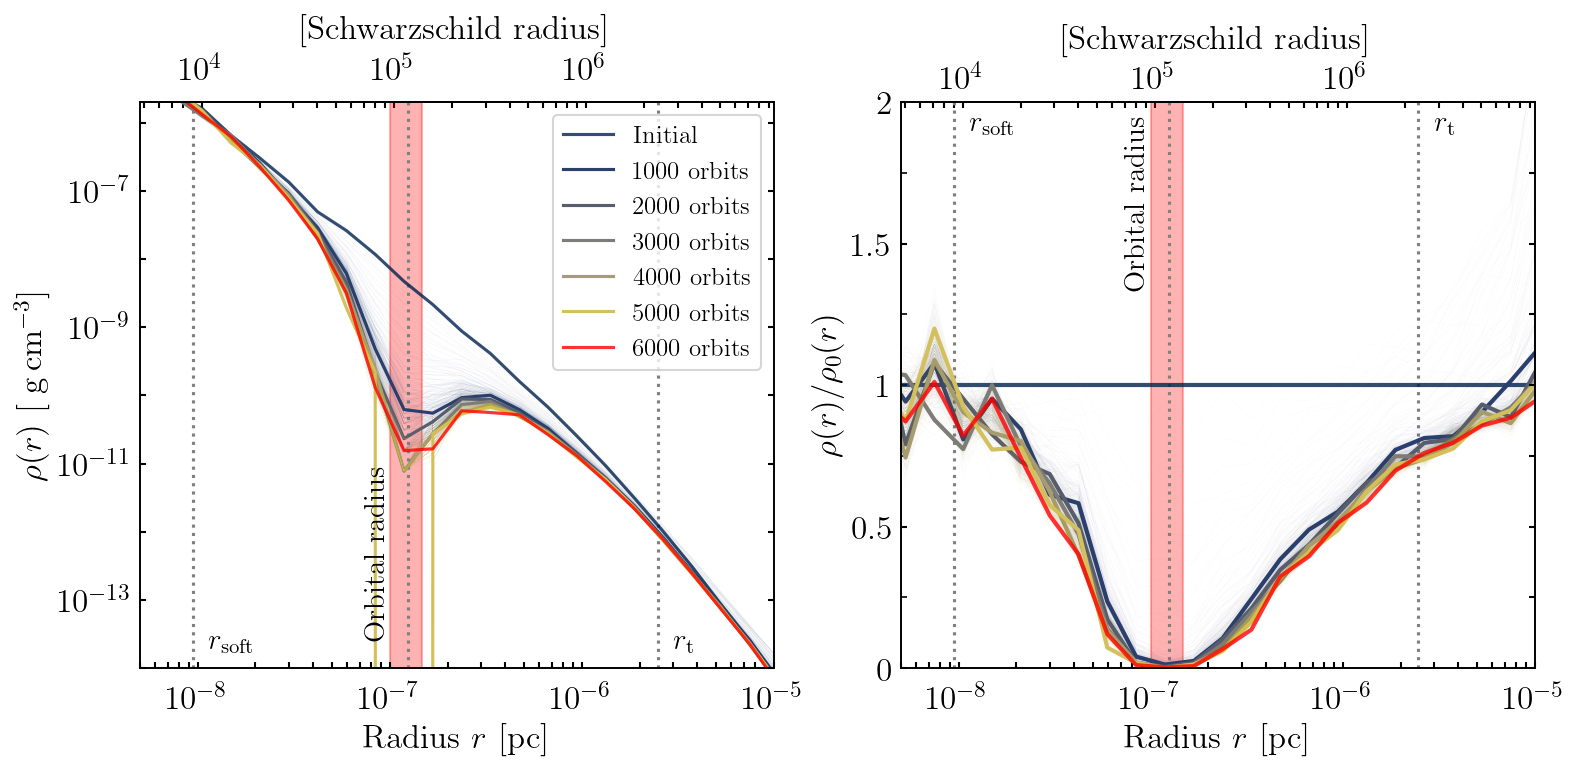

In [40]:
# Create figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5),  # 12" width, 5" height
                               sharex=True,             # Share x-axis scale/labels
                               gridspec_kw={'wspace': 0.2})  # Reduce space between plots

#choose the value of gamma
gamma=2.30

#plots the first simulation of the list
key=list(data_dict[gamma].keys())[0]

profiles=data_dict[gamma][key]["profiles"]
bins=data_dict[gamma][key]["profile_bins"]

cmap = plt.get_cmap('cividis')
colors = cmap(np.linspace(0, 1, len(profiles)))

ax1.axvline(a_i/u.pc, linestyle=':', color='gray')
ax1.axvspan((a_i-r_2)/u.pc, (a_i+r_2)/u.pc , alpha=0.3, color='red')

ax1.axhline(1, linestyle='--', color='k')
ax1.axvline(eps1/u.pc, linestyle=':', color='gray')
ax1.axvline(r_t/u.pc, linestyle=':', color='gray')


ax2.axvline(a_i/u.pc, linestyle=':', color='gray')
ax2.axvspan((a_i-r_2)/u.pc, (a_i+r_2)/u.pc , alpha=0.3, color='red')


ax2.axvline(eps1/u.pc, linestyle=':', color='gray')
ax2.axvline(r_t/u.pc, linestyle=':', color='gray')

ax2.semilogx(bins/u.pc, np.ones(len(profiles[0])), color=colors[0],  linewidth=2, alpha=.8, label="Initial")
ax1.semilogx(bins/u.pc, profiles[0]/(u.g/u.cm**3), color=colors[0], linewidth=1.5, alpha=.8, label="Initial")   



for i, profile in enumerate(profiles):
    
    norbits=10*i
    

       
    if norbits%1000==0 and norbits>0:  
        
        with np.errstate(divide='ignore', invalid='ignore'):             
            ratio= profile/profiles[0]
            

    
        ax2.semilogx(bins/u.pc, ratio , color=colors[i], label=f"{norbits} orbits", linewidth=2)       
        ax1.loglog(bins/u.pc, profile/(u.g/u.cm**3), label=f"{norbits} orbits",color=colors[i], linewidth=1.5)
    else:

        with np.errstate(divide='ignore', invalid='ignore'):
            ratio= profile/profiles[0]

        
        ax2.semilogx(bins/u.pc, ratio, color=colors[i], linewidth=.05, alpha=.1)
        ax1.loglog(bins/u.pc, profile/(u.g/u.cm**3), color=colors[i], alpha=.1,linewidth=.1)
        


ax2.semilogx(bins/u.pc, ratio, "red", linewidth=2, alpha=.8, label="6000 orbits")
    
ax1.semilogx(bins/u.pc, profile/(u.g/u.cm**3), "red", linewidth=1.5, alpha=.8, label="6000 orbits")       
    
    
ax1.set_xlim(5e-9, 1e-5)
ax1.set_ylim(1e-14, 2e-6)


ax1.text(1.2*eps1/u.pc, 2e-14, "$r_\mathrm{soft}$", fontsize=14)
ax1.text(1.2*r_t/u.pc, 2e-14, "$r_\mathrm{t}$", fontsize=14)
ax1.text(a_i/u.pc/1.7, 3e-14, "Orbital radius ", fontsize=14, rotation=90)

ax2.text(1.2*eps1/u.pc, 1.9, "$r_\mathrm{soft}$", fontsize=14)
ax2.text(1.2*r_t/u.pc, 1.9, "$r_\mathrm{t}$", fontsize=14)
ax2.text(a_i/u.pc/1.7, 1.35, "Orbital radius ", fontsize=14, rotation=90)


ax1.tick_params(axis='both', which='both', direction='in', length=3)
ax1.tick_params(axis='x', which='major', pad=8)   # Increase pad as needed
ax1.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=100)) 


def format_decade_label_2(value, pos=None):
    exponent = int(np.log10(value))
    if (exponent+1) % 2 == 0:  # Only label every 2th decade
        return r'$10^{{{}}}$'.format(exponent)
    return ''  # Empty label for other decades

ax1.yaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_2))

ax1.set_xlabel(r"Radius $ r $ [pc]")
ax1.set_ylabel(r"$\rho(r)$ [ $ \mathrm{g}\,\mathrm{cm}^{-3}$]")

ax1_right = ax1.twinx()  
ax1_right.set_ylim(1e-14, 2e-6)
ax1_right.set_yscale("log")
ax1_right.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=100))
ax1_right.yaxis.set_major_formatter(ticker.FuncFormatter(format_decade_label_2))
ax1_right.tick_params(axis='both', which='both', direction='in', length=3)
ax1_right.tick_params(right=True, labelright=False)



secax1 = ax1.secondary_xaxis(
    'top',
    functions=(
        lambda r: r * u.pc/r_s,  # Convert g/cm³ → GeV/c²/cm³
        lambda x: x *r_s/u.pc  # Inverse
    ))
secax1.tick_params(axis='x', which='both', direction='in', length=3, pad=8)
secax1.set_xlabel(r"[Schwarzschild radius]", labelpad=8)

ax2.set_ylim(0, 2)

ax2.yaxis.set_major_locator(plt.MultipleLocator(0.5))
ax2.yaxis.set_minor_locator(plt.MultipleLocator(0.25))


ax2.tick_params(axis='both', which='both', direction='in', length=3)
ax2.tick_params(axis='x', which='major', pad=8)   # Increase pad as needed
ax2.tick_params(axis='y', which='minor', length=3, width=0.8)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}' if int(10*y) % 10 == 0 else f'{y:.1f}'))


ax1.legend(fontsize=12, loc="upper right")

ax2.set_xlabel(r"Radius $r$ [pc]")
ax2.set_ylabel(r"$\rho(r)/ \rho_0(r)$ ")

ax2_right = ax2.twinx()  
ax2_right.yaxis.set_major_locator(plt.MultipleLocator(0.5))
ax2_right.yaxis.set_minor_locator(plt.MultipleLocator(0.25))
ax2_right.set_ylim(0, 2)

ax2_right.tick_params(axis='both', which='both', direction='in', length=3)
ax2_right.tick_params(right=True, labelright=False)
ax2_right.tick_params(axis='y', which='minor', length=3) 

secax2 = ax2.secondary_xaxis(
    'top',
    functions=(
        lambda r: r * u.pc/r_s,  # Convert g/cm³ → GeV/c²/cm³
        lambda x: x *r_s/u.pc  # Inverse
    ))
secax2.tick_params(axis='x', which='both', direction='in', length=3)
secax2.set_xlabel(r"[Schwarzschild radius]", labelpad=8)

#plt.savefig('../plots/depletion_pair.pdf',transparent=False,bbox_inches='tight')

plt.show()

## Period decay 

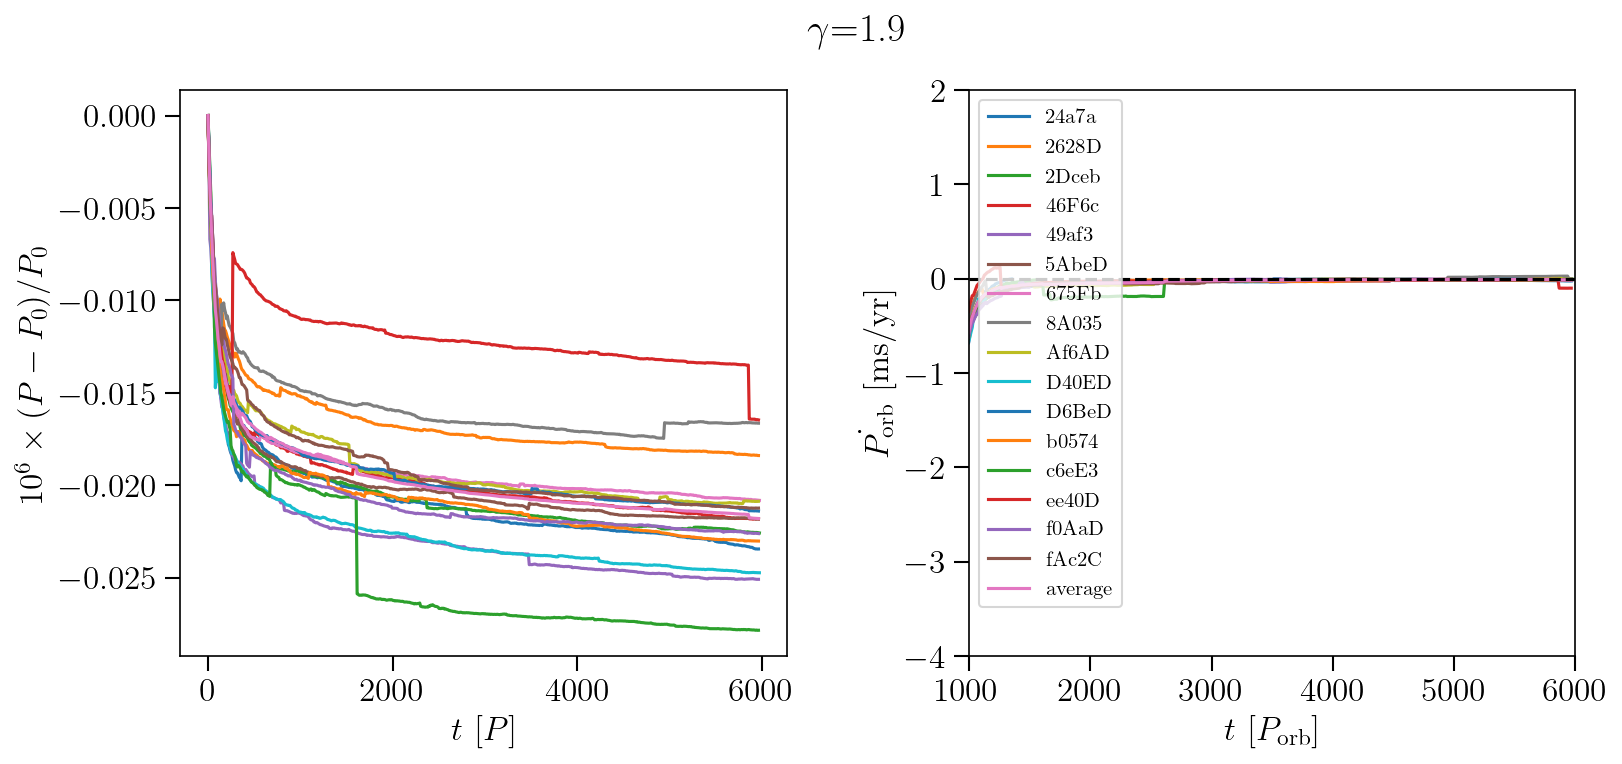

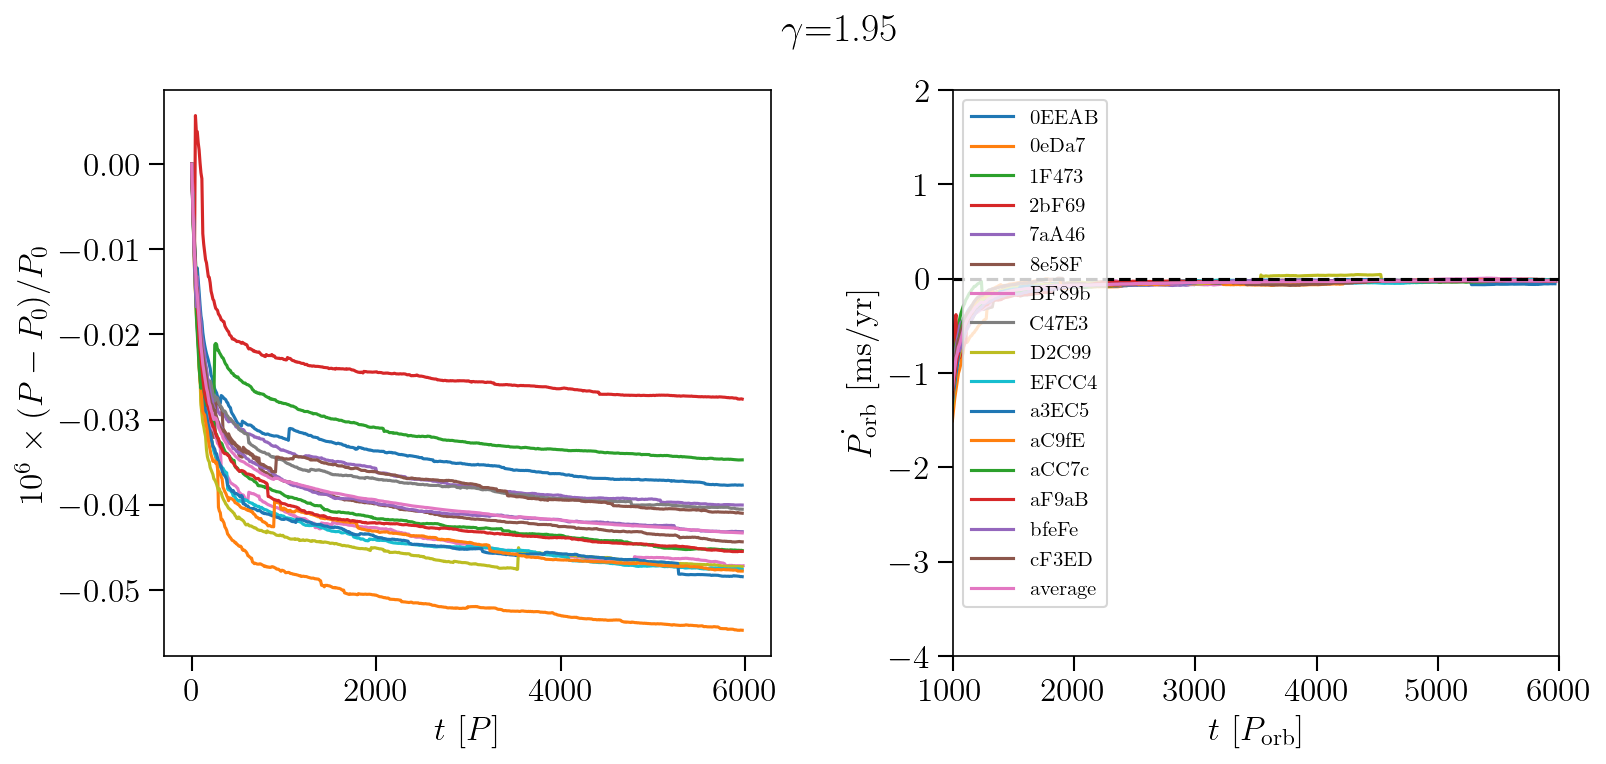

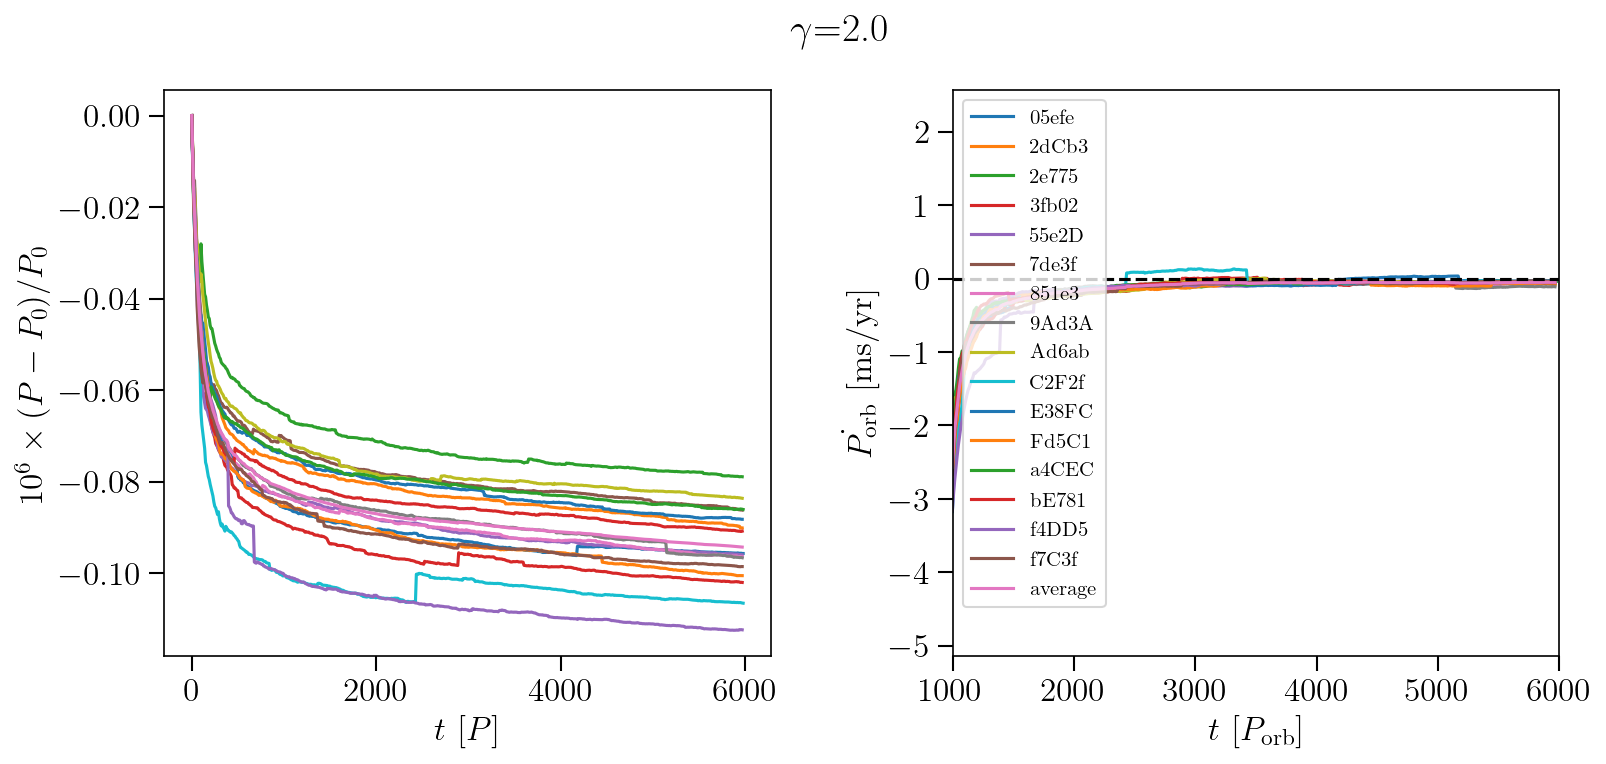

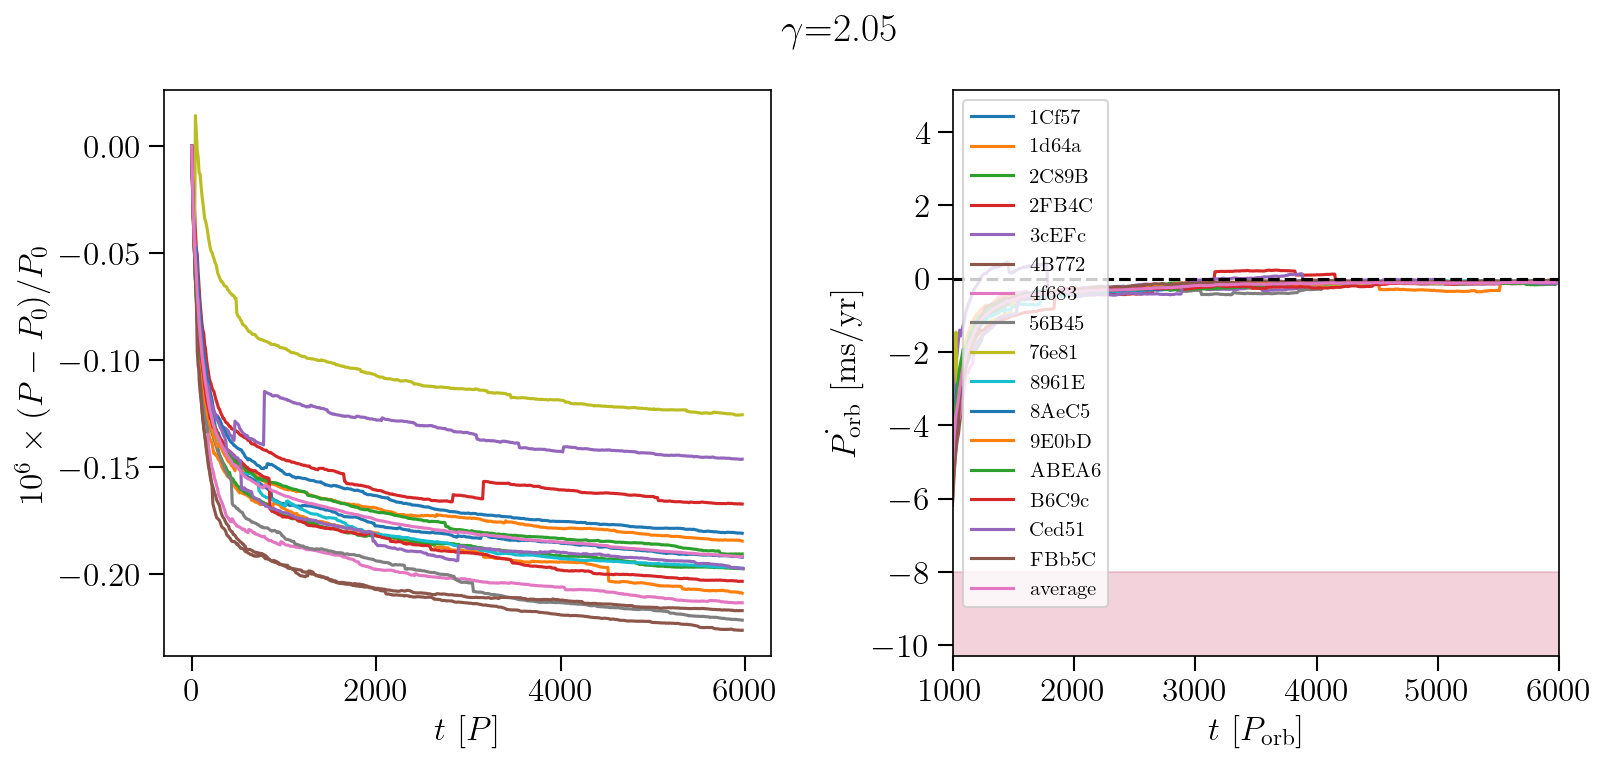

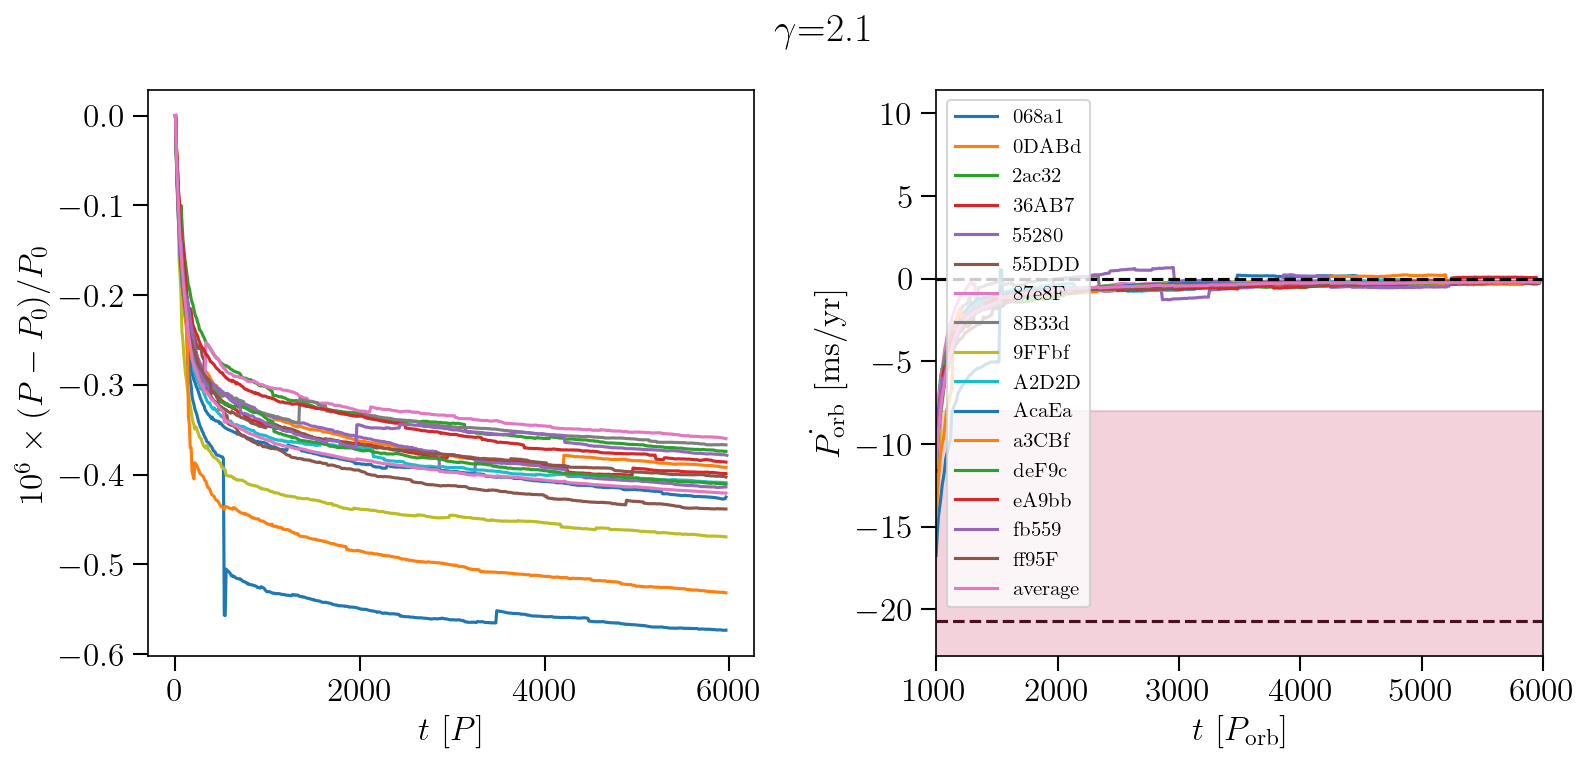

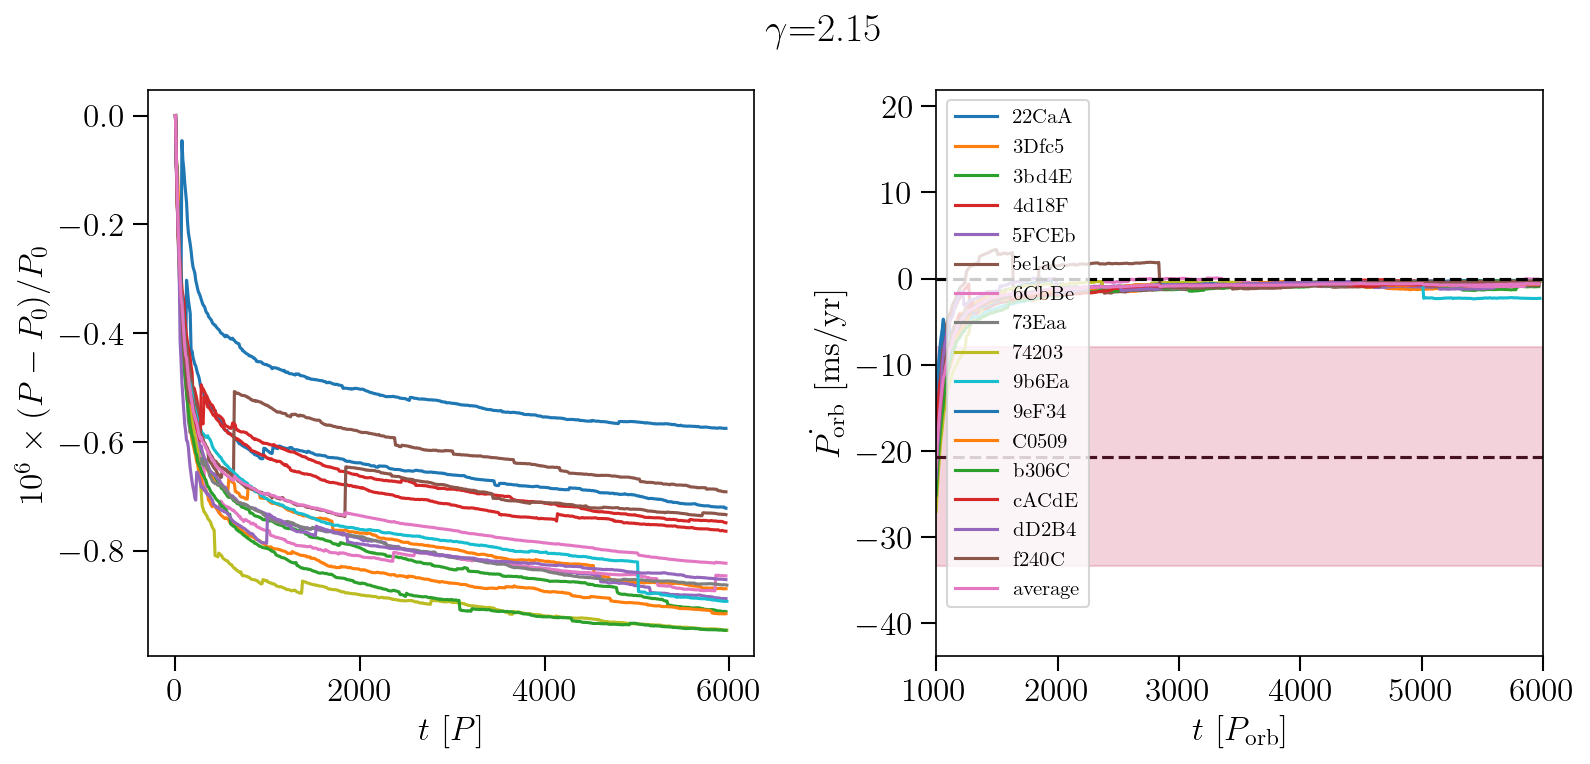

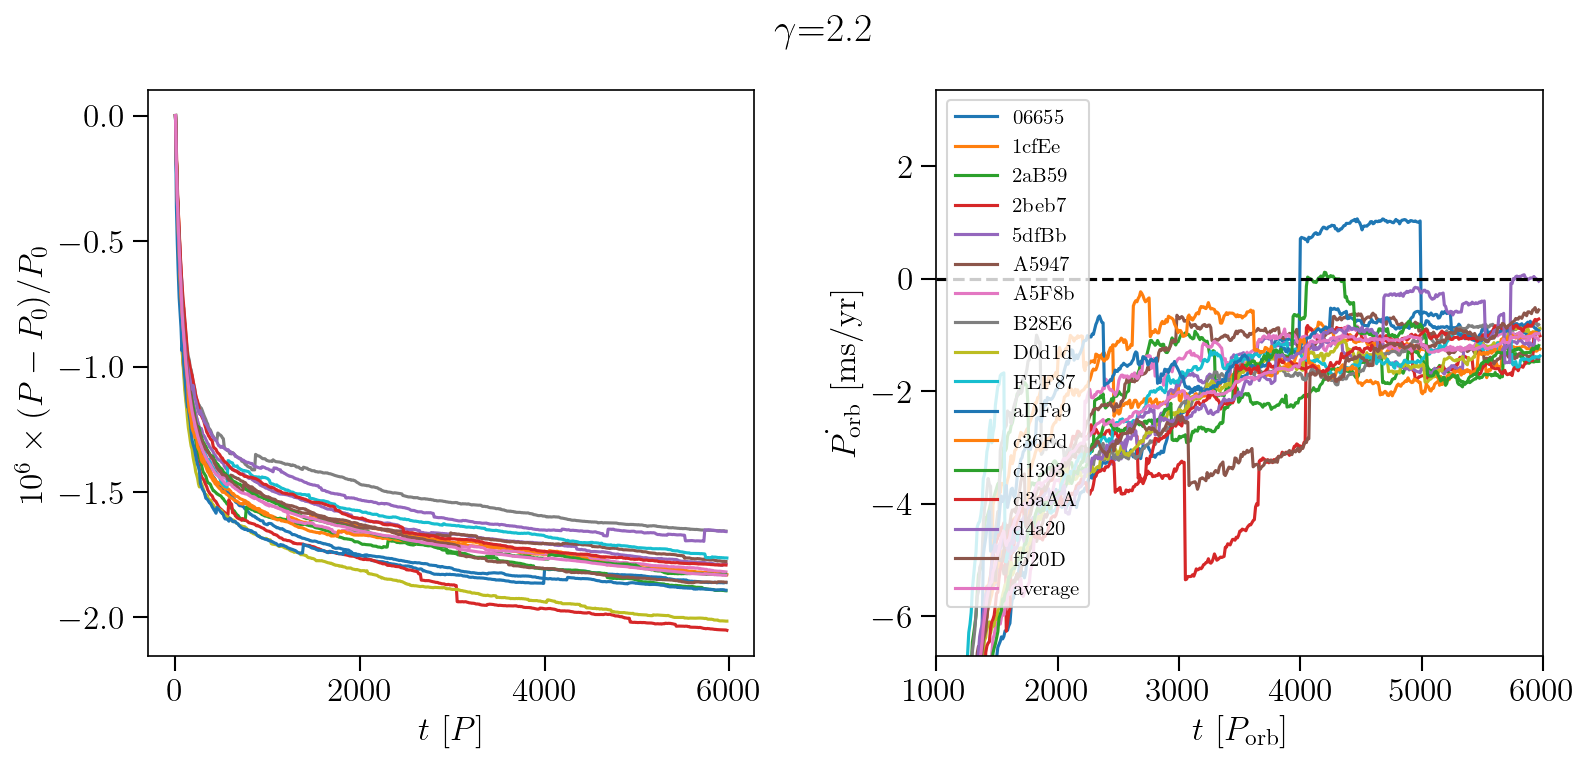

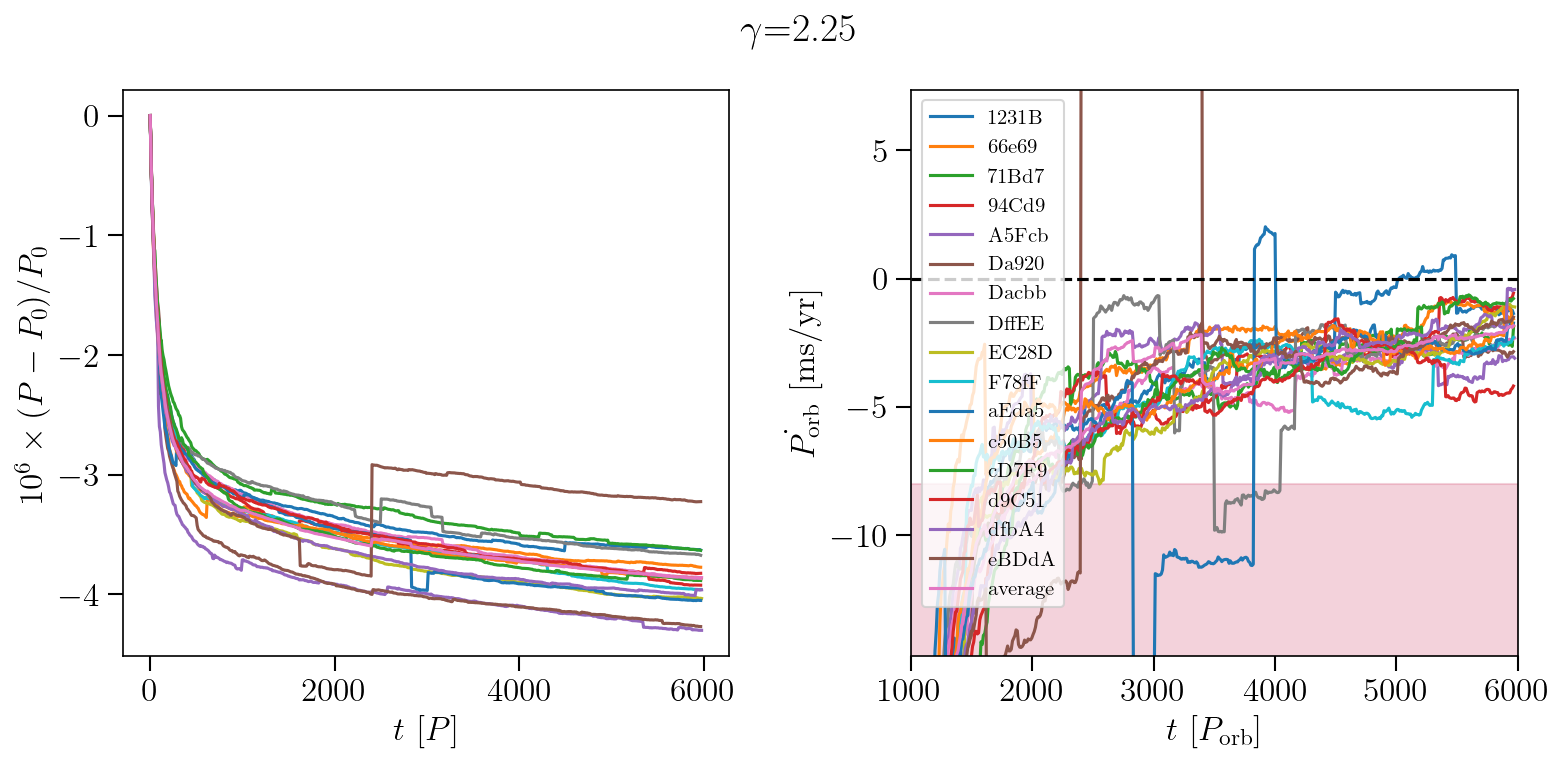

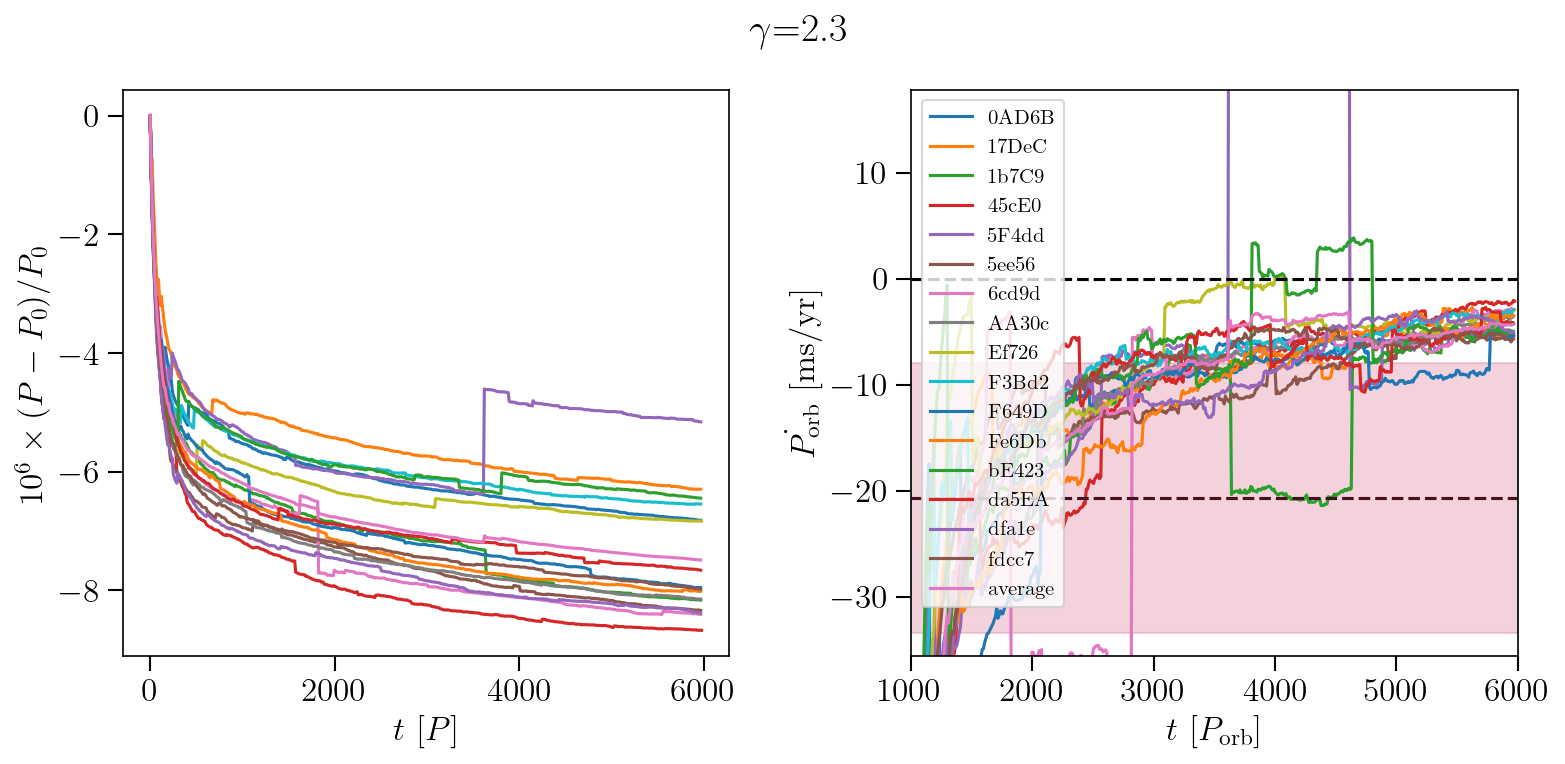

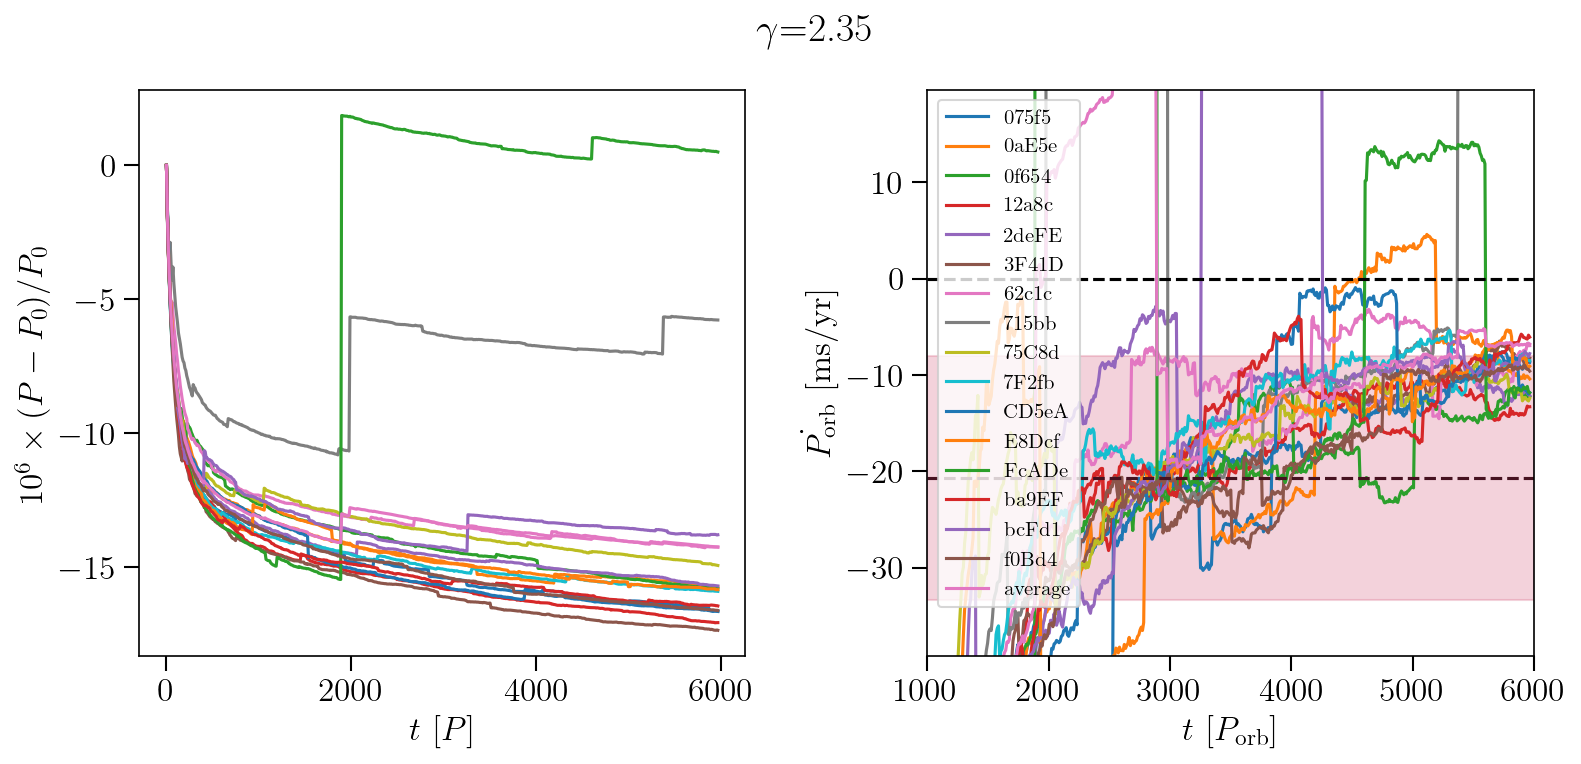

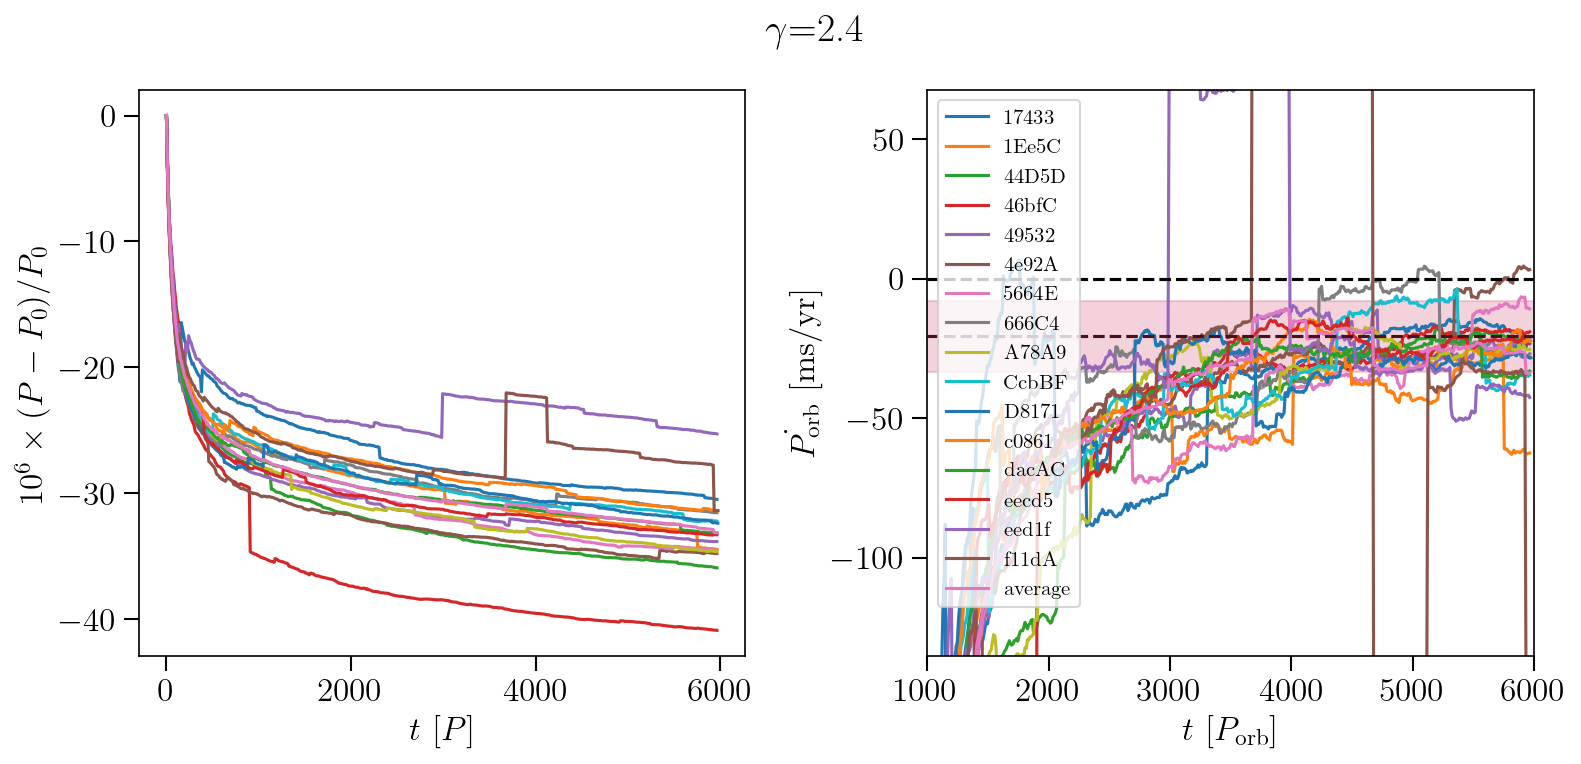

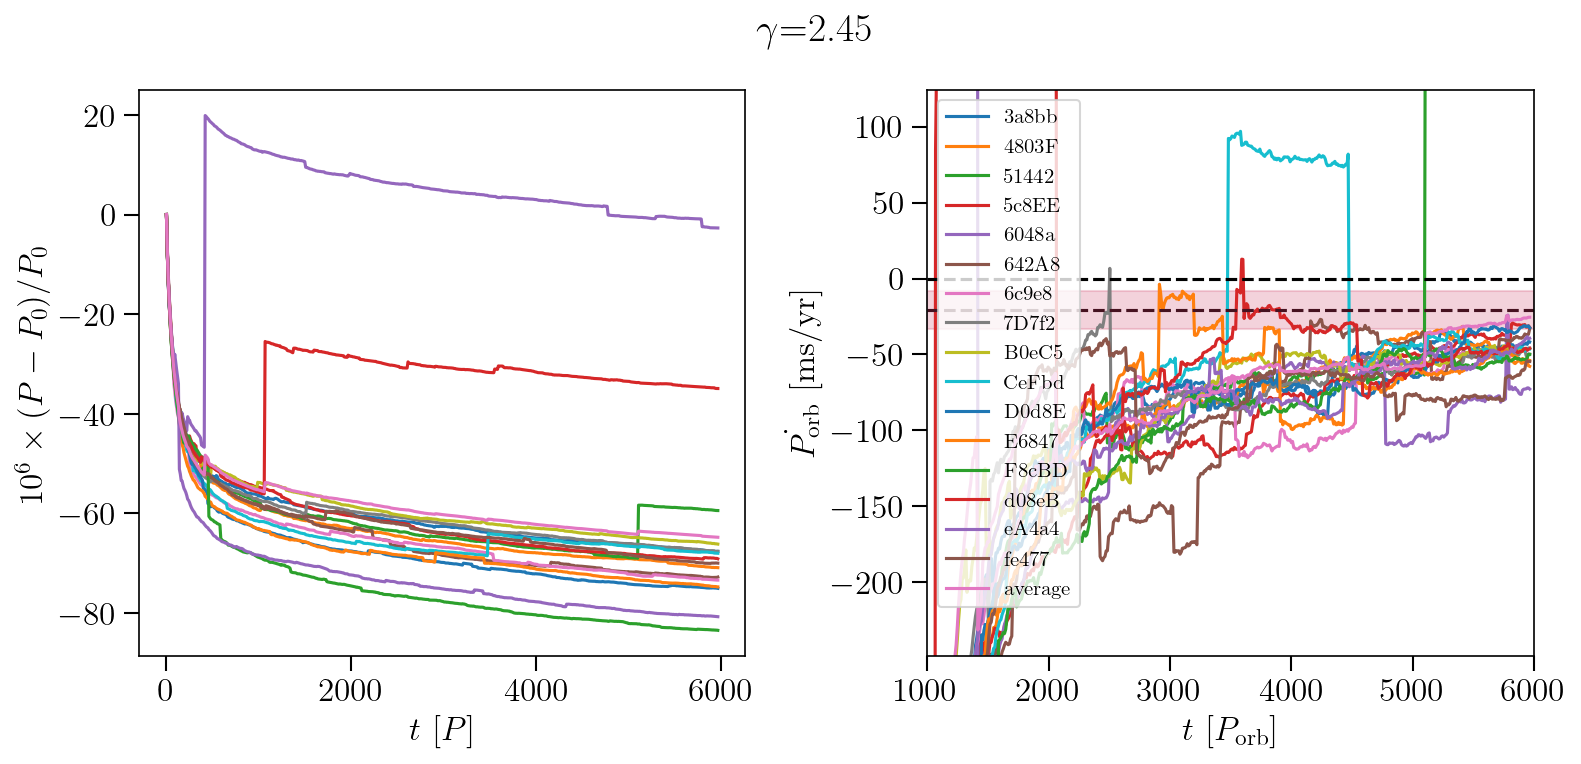

In [41]:

for gamma in gammalist:   
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5),  # 12" width, 5" height
                               sharex=False,             # Share x-axis scale/labels
                               gridspec_kw={'wspace': 0.3},
                               ) 
    
    plt.suptitle(f"$\gamma$={gamma}")
    
    
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)   
        try:
            fig.tight_layout()
        except Exception as e:        
            print(f"Layout error: {e}")
        
        
        
    for IDhash in data_dict[gamma].keys():

        data=data_dict[gamma][IDhash]
        ax2.plot(data["data/t"][1:]/T_orb, data["Pdot"]/u.ms*u.yr, label = IDhash)
        
        #This is what it looks like if I derive without smoothing first
        #ax2.plot(data["data/t"][1:]/T_orb, data["diff_Torb"]/u.ms*u.yr, label = IDhash)
        
            
        ax1.plot(data["data/t"]/T_orb, (data["Torb"]-data["Torb"][0])*10**6/data["Torb"][0], label = IDhash)


    ax1.set_xlabel(r"$t$ [$P$]")
    ax1.set_ylabel(r"$10^6 \times (P-P_0)/P_0$ ")
    

    plt.legend(fontsize=10, loc= "upper left")
    
    
    if (gamma<2.2):
        ymin=2*min(-2, np.nanmin(data["Pdot"][10:-1]/u.ms*u.yr))
    else:
        ymin=2*min(-2, np.nanmin(data["Pdot"][200:-1]/u.ms*u.yr))
        
    ymax=-ymin/2

    ax2.set_ylim(ymin, ymax)
    ax2.set_xlim(1000, 6000)


    ax2.axhline(0, linestyle='--', color='k')
    ax2.axhline(dTobs, linestyle='--', color=mycolor)
    ax2.axhspan((dTobs-dTerr), (dTobs+dTerr) , alpha=0.3, color=myshade)



    ax2.set_xlabel(r"$t$ [$P_\mathrm{orb}$]")
    ax2.set_ylabel(r"$\dot{P_\mathrm{orb}}$ [ms/yr]")

plt.show()

##### Long run (15k orbits)

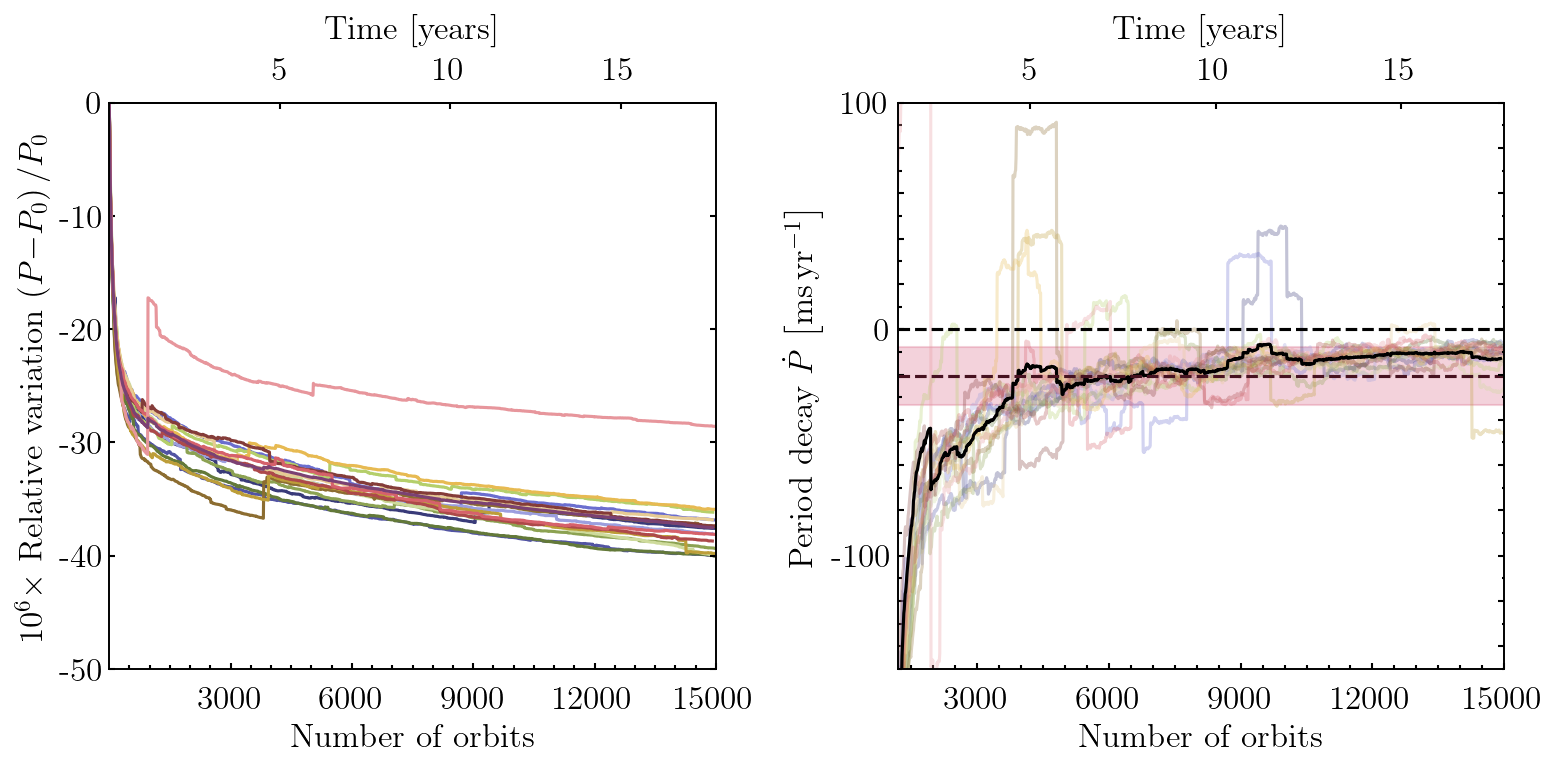

In [42]:
# Create figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5),  # 12" width, 5" height
                               sharex=False,             # Share x-axis scale/labels
                               gridspec_kw={'wspace': 0.3})  # Reduce space between plots



gamma=g_long

colors = plt.cm.tab20b.colors

for i, IDhash in enumerate(list(data_long[gamma].keys())):

    data=data_long[gamma][IDhash]
    if IDhash=="average":
        ax2.plot(data["data/t"][1:]/T_orb, data["Pdot"]/u.ms*u.yr, color="k")
    else:
        ax2.plot(data["data/t"][1:]/T_orb, data["Pdot"]/u.ms*u.yr, label = IDhash, color=colors[i], alpha=0.3)
    ax1.plot(data["data/t"]/T_orb, -(data["Torb"][0]-data["Torb"])*10**6/data["Torb"][0], label = IDhash, color=colors[i])
    
    
    
ax2.axhline(0, linestyle='--', color='k')
#ax2.text(1250, -3.8, "Observed", fontsize=13, color= "black")
ax2.axhline(dTobs, linestyle='--', color=mycolor)
ax2.axhspan((dTobs-dTerr), (dTobs+dTerr) , alpha=0.3, color=myshade)


ax2.set_ylim(-150, 100)
ax2.set_xlim(1200, 15000)
ax1.set_ylim(-50, 0)
ax1.set_xlim(1, 15000)


ax2.tick_params(axis='both', which='both', direction='in', length=3)
ax2.tick_params(axis='both', which='minor', direction='in', length=2)
ax2.tick_params(axis='x', which='major', pad=8)   # Increase pad as needed

ax2.yaxis.set_major_locator(plt.MultipleLocator(20))
ax2.yaxis.set_minor_locator(plt.MultipleLocator(10))

ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}' if y % 50 == 0 else f''))


ax2_right = ax2.twinx()  
ax2_right.set_ylim(-150, 100)

ax2_right.yaxis.set_major_locator(plt.MultipleLocator(20))
ax2_right.yaxis.set_minor_locator(plt.MultipleLocator(10))
ax2_right.tick_params(axis='both', which='both', direction='in', length=3)
ax2_right.tick_params(axis='y', which='minor', direction='in', length=1)
ax2_right.tick_params(right=True, labelright=False)

ax2.xaxis.set_major_locator(plt.MultipleLocator(3000))
ax2.xaxis.set_minor_locator(plt.MultipleLocator(500))


ax1.tick_params(axis='both', which='both', direction='in', length=3)
ax1.tick_params(axis='both', which='minor', direction='in', length=2)
ax1.tick_params(axis='x', which='major', pad=8)   # Increase pad as needed
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}' if y%10==0 else f''))


#ax1.yaxis.set_major_locator(plt.MultipleLocator(2e-6))
#ax1.yaxis.set_minor_locator(plt.MultipleLocator(1e-6))

ax1.xaxis.set_major_locator(plt.MultipleLocator(3000))
ax1.xaxis.set_minor_locator(plt.MultipleLocator(500))

ax1_right = ax1.twinx()  
ax1_right.set_ylim(-50, 0)

#ax1_right.yaxis.set_major_locator(plt.MultipleLocator(2e-6))
#ax1_right.yaxis.set_minor_locator(plt.MultipleLocator(1e-6))
ax1_right.tick_params(axis='both', which='both', direction='in', length=3)
ax1_right.tick_params(axis='y', which='minor', direction='in', length=3)
ax1_right.tick_params(right=True, labelright=False)
    
    
ax1.set_xlabel(r"Number of orbits")
ax1.set_ylabel(r" $10^{6} \times $ Relative variation " +r"$ \left(P \mathrm{-} P_0 \right)/P_0  $")


ax2.set_xlabel(r"Number of orbits")
ax2.set_ylabel(r"Period decay $\dot{P} $   $\left[ \mathrm{ms} \, \mathrm{yr}^{\mathrm{-}1} \right] $")


secax1 = ax1.secondary_xaxis(
    'top',
    functions=(
        lambda N: N * T_orb/u.yr,  # Convert g/cm³ → GeV/c²/cm³
        lambda t: t *u.yr/T_orb  # Inverse
    ))
secax1.tick_params(axis='x', which='both', direction='in', length=3, pad=8)
secax1.set_xlabel(r"Time [years]", labelpad=8)
#secax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}' if int(10*y) % 10 == 0 else f'{y:.2f}'))

secax2 = ax2.secondary_xaxis(
    'top',
    functions=(
        lambda N: N * T_orb/u.yr,  # Convert g/cm³ → GeV/c²/cm³
        lambda t: t *u.yr/T_orb  # Inverse
    ))
secax2.tick_params(axis='x', which='both', direction='in', length=3, pad=8)
secax2.set_xlabel(r"Time [years]", labelpad=8)
secax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}' if int(10*y) % 10 == 0 else f'{y:.1f}'))
  
#ax2.axvline(6000, linestyle="dotted", linewidth="2", color="k")   

#ax1.text(12000, -2.76, r"$\gamma=2.2$", fontsize=16, color= "black")
#ax2.text(12000, -4.5, r"$\gamma=2.2$", fontsize=16, color= "black")


#plt.savefig('../plots/NM_long_decay.pdf',transparent=False, bbox_inches='tight', dpi=300)

plt.show()

## Final Pdot with errors 

In [43]:
dTdt_values={}

dTdt_central_11={}
dTdt_mean={}
dTdt_sigma={}


for gamma in gammalist:
    
    dTdt_values[gamma]=[]
    
    #read the last value of Pdot for each realizations
    for ID in data_dict[gamma].keys():

        data= data_dict[gamma][ID]

        last_element=data["Pdot"][-1]
        dTdt= last_element/u.ms*u.yr
        dTdt_values[gamma].append(dTdt)
        
     
    xi=dTdt_values[gamma]
    
    median=np.median(xi)
    
    diff = np.abs(xi - median)
    
    sorted_indices = np.lexsort((xi, diff))
    
    central_11=[xi[i] for i in sorted_indices[:11]]
    
    #central_value=xi[sorted_indices[0]]
     
    dTdt_central_11[gamma]=np.sort(central_11)
    
    dTdt_mean[gamma]=(dTdt_central_11[gamma][0]+dTdt_central_11[gamma][-1])/2
    dTdt_sigma[gamma]=(dTdt_central_11[gamma][-1]-dTdt_central_11[gamma][0])/2



means=np.asarray([dTdt_mean[gamma] for gamma in gammalist])
sigmas=np.asarray([dTdt_sigma[gamma] for gamma in gammalist])
values=np.asarray([dTdt_values[gamma] for gamma in gammalist])

np.savez('C_Pdot.npz', array1=values, array2=means, array3=sigmas)

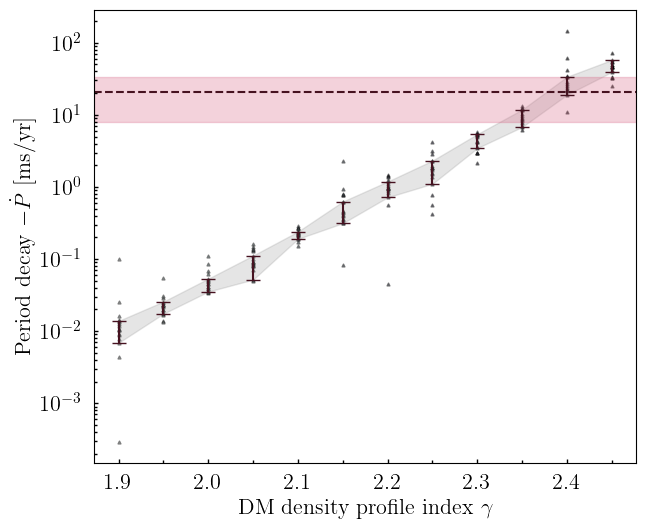

In [44]:
plt.figure(figsize=(7,6), dpi=100)

cmap = plt.get_cmap('bone')
colors = cmap(np.linspace(0,1, len(gammalist)+2))


def plotstuff(ax, values, means, sigmas, dTobs, dTerr, color, shade):
    # Plot individual points
    for i, gamma in enumerate(gammalist):       
        mean=-means[i]
        sigma=sigmas[i]
        points= -values[i]

        ax.scatter(gamma*np.ones(len(points)), points, alpha=.5, s=4, marker="^", color=colors[-(i+2)], edgecolor='black')
        # Plot standard deviations as vertical error bars
        ax.errorbar(gamma, mean, yerr=sigma, fmt='none', ecolor=color, capsize=5)
       
    ax.fill_between(gammalist, y1=-(means-sigmas), y2=-(means+sigmas), color='gray',alpha=.2)   
    ax.axhline(-dTobs, linestyle='--', color=color)
    ax.axhspan((-dTobs-dTerr), (-dTobs+dTerr) , alpha=0.3, color=shade)
    
    ax.set_yscale("log")
    
ax=plt.gca()

plotstuff(ax, values, means, sigmas, dTobs, dTerr, mycolor, myshade)


ax.set_ylabel(r" Period decay $-\dot{P}$ [ms/yr]")
ax.set_xlabel(r'DM density profile index $\gamma$') 

ax.tick_params(axis='both', which='both', direction='in', length=2)
ax.tick_params(axis='both', which='major', direction='in', length=3, pad=8)


ax.xaxis.set_major_locator(plt.MultipleLocator(.1))
ax.xaxis.set_minor_locator(plt.MultipleLocator(.05))



plt.show()